# 🐍 Notebook 0 — Python for This Course
**Monte Carlo for Polymer Reaction Engineering**

Never written Python before? Start here. We'll learn only what the course uses, one small step at a time, and every example is about polymers.

| | |
|---|---|
| ⏱ Time | ~40 min |
| 🎯 You will learn | run code in Colab · variables · `if` · `while` · `for` · lists and dictionaries · functions · NumPy · a first plot · how to turn the book's pseudocode into Python |
| 📖 Companion book | *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture* |

## 1 · How Colab works
- Text like this is a **text cell**. Grey boxes are **code cells**.
- To run a code cell: click it, then press **Shift + Enter** (or click ▶ on its left).
- The output appears right below the cell.
- Run the cells **from top to bottom**. A cell can use what earlier cells created, but only if you ran them.
- If things get confusing: **Runtime → Restart and run all** starts everything fresh.

Try it: run the cell below.

In [1]:
print("Hello, polymer world!")

Hello, polymer world!


## 2 · Variables: giving names to numbers
A **variable** stores a value under a name. The `=` sign means *"store this value"*, not "is equal to".

In [2]:
monomer_mass = 104.15     # g/mol, styrene
chain_length = 500        # repeat units

Everything after `#` is a **comment**: Python ignores it. It's there for humans.

Now we can calculate with these names:

In [3]:
molecular_weight = monomer_mass * chain_length
print(molecular_weight)

52075.0


To print text and numbers together, put an `f` before the quotes and the variable inside `{ }`:

In [4]:
print(f"A chain of {chain_length} units weighs {molecular_weight} g/mol")

A chain of 500 units weighs 52075.0 g/mol


## 3 · Random numbers
Monte Carlo runs on random numbers. Python's `random` module gives us one with `random.random()`: a number between 0 and 1, every value equally likely.

First we **import** the module (load it), once:

In [5]:
import random

Now run the next cell several times. You get a different number each time.

In [6]:
Rnd = random.random()
print(Rnd)

0.44930565163373215


Sometimes we want the *same* random numbers every time (to compare results). `random.seed(...)` does that. Run this cell twice: same number both times.

In [7]:
random.seed(1)
print(random.random())

0.13436424411240122


## 4 · Decisions with `if`
A polymer radical either **propagates** (adds a monomer) or **stops**. If the probability of propagation is `Pp = 0.9`, we decide like this:

> draw `Rnd`; if `Rnd ≤ Pp`, the chain propagates.

In Python, `<=` means ≤. Notice the colon `:` and the **indentation** (4 spaces): the indented lines belong to the `if`.

In [8]:
Pp = 0.9
Rnd = random.random()

if Rnd <= Pp:
    print("propagate")
else:
    print("stop")

propagate


Run it a few times. About 9 times out of 10 you should see "propagate".

## 5 · Repeating with `while`
A `while` loop repeats its indented lines **as long as** its condition is true. Here: keep adding monomers while the random number says "propagate".

In [9]:
Pp = 0.9
n = 1                              # the chain starts with one unit

while random.random() <= Pp:       # propagate?
    n = n + 1                      # yes: add one unit

print(f"The chain stopped at length {n}")

The chain stopped at length 16


That's it — **you just simulated a polymer chain**. Run it a few times: each chain has a different length.

💡 `n = n + 1` is so common that Python has a shortcut: `n += 1`. Both mean the same thing.

## 6 · Repeating a fixed number of times with `for`
A `for` loop repeats a block a set number of times. `range(5)` gives the numbers 0, 1, 2, 3, 4.

In [10]:
for i in range(5):
    print(f"This is repetition number {i}")

This is repetition number 0
This is repetition number 1
This is repetition number 2
This is repetition number 3
This is repetition number 4


Now combine both loops: the `for` loop makes 5 chains, the `while` loop grows each one.

In [11]:
for i in range(5):
    n = 1
    while random.random() <= Pp:
        n += 1
    print(f"chain {i}: length {n}")

chain 0: length 1
chain 1: length 4
chain 2: length 18
chain 3: length 6
chain 4: length 28


Look at the indentation: the `while` sits **inside** the `for`, and `n += 1` sits **inside** the `while`.

## 7 · Lists: storing many results
A **list** holds many values in order. Start empty with `[]`, then add values with `.append(...)`.

In [12]:
lengths = []

for i in range(10):
    n = 1
    while random.random() <= Pp:
        n += 1
    lengths.append(n)

print(lengths)

[5, 6, 5, 69, 11, 5, 8, 4, 19, 6]


Useful things to do with a list:

In [13]:
print(len(lengths))     # how many values
print(max(lengths))     # the largest
print(sum(lengths))     # the total

10
69
138


⚠️ **Python counts from 0.** The first element is `lengths[0]`, the second is `lengths[1]`.

In [14]:
print(lengths[0])       # the first chain
print(lengths[1])       # the second chain

5
6


### Dictionaries: looking things up by name
A **dictionary** stores pairs: a *key* and its *value*, written `key: value` inside `{ }`. Here, the key is a monomer and the value its molar mass:

In [15]:
molar_mass = {"styrene": 104.15, "MMA": 100.12}
print(molar_mass["MMA"])

100.12


You can check whether a key is in the dictionary with `in`:

In [16]:
print("styrene" in molar_mass)
print("ethylene" in molar_mass)

True
False


## 8 · Functions: naming a piece of code
When we use the same steps many times, we wrap them in a **function** with `def`. The function takes inputs (here `Pp`) and gives back a result with `return`.

In [17]:
def grow_chain(Pp):
    n = 1
    while random.random() <= Pp:
        n += 1
    return n

Running that cell only *defines* the function; nothing happens yet. Now we **call** it:

In [18]:
print(grow_chain(0.9))
print(grow_chain(0.99))

5
443


## 9 · Counting chains by length: the vector `D`
The book stores results in a **counting vector** `D`: `D[n]` is the number of chains with length `n`.

Start with a list of zeros, long enough for the longest chain we expect:

In [19]:
D = [0] * 200          # 200 zeros: D[0], D[1], ..., D[199]
print(D[:10])          # show the first 10

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


Each time a chain is made, add 1 to its slot:

In [20]:
for i in range(1000):
    n = grow_chain(0.9)
    if n < 200:
        D[n] += 1

print(D[:15])

[0, 106, 81, 90, 64, 75, 56, 60, 50, 46, 36, 37, 28, 37, 24]


`D[3]` is now the number of chains that had exactly 3 units. (We skip the rare chain longer than 199, so it doesn't fall off the end of the list.)

## 10 · NumPy: fast arrays
**NumPy** is the standard library for numbers in Python. We import it once, with the short name `np`:

In [21]:
import numpy as np

A NumPy **array** is like a list, but you can do maths on all of it at once:

In [22]:
D = np.array(D)
print(D.sum())          # total number of chains

1000


In [23]:
fraction = D / D.sum()  # divide every entry at once
print(fraction[:6])

[0.    0.106 0.081 0.09  0.064 0.075]


## 11 · A first plot
**Matplotlib** draws graphs. We import its plotting part as `plt`:

In [24]:
import matplotlib.pyplot as plt

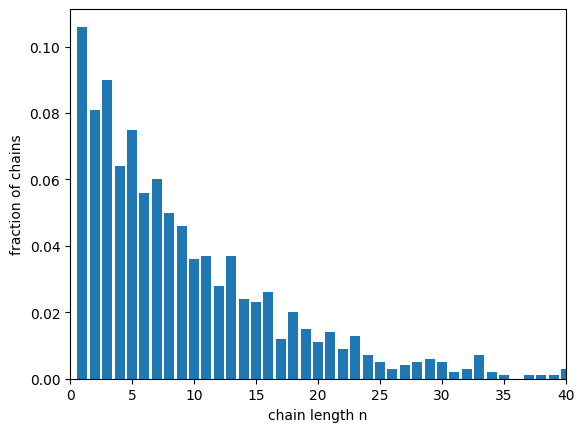

In [25]:
plt.bar(range(200), fraction)
plt.xlim(0, 40)
plt.xlabel("chain length n")
plt.ylabel("fraction of chains")
plt.show()

You just made a **chain length distribution**: many short chains, few long ones. This is exactly what Notebook 2 builds on.

💡 In the other notebooks, plotting code is tucked into collapsed cells titled *"Plot …"* so you can focus on the simulation. Click *"Show code"* on any of them to see how the figure is made.

## 12 · From the book's pseudocode to Python
The book writes algorithms in **pseudocode**. Here is how its symbols become Python:

| Book pseudocode | Python | Meaning |
|---|---|---|
| `n ← 1` | `n = 1` | store a value |
| `Rnd ← random(0, 1)` | `Rnd = random.random()` | random number in (0, 1) |
| `if Rnd ≤ Pp then … else … end` | `if Rnd <= Pp:` … `else:` … | decision (use indentation, no `end`) |
| `while true do … break … end` | `while True:` … `break` | repeat until `break` |
| `repeat … until condition` | `while True:` … `if condition: break` | repeat at least once |
| `for i ← 1 to N do` | `for i in range(N):` | repeat N times |
| `D[n] ← D[n] + 1` | `D[n] += 1` | add one to a counter |
| `x ← x + 1` | `x += 1` | increase by one |

⚠️ **Counting from 0 vs 1.** In the book, `for i ← 1 to N` counts 1, 2, …, N. In Python, `range(N)` counts 0, 1, …, N−1. It still repeats N times, so for loops that just *repeat* this doesn't matter. It matters when the number is used as a **position** in a list, because Python's first position is 0.

### Worked example
The book's first algorithm (Chapter 2) in pseudocode:

```
for i ← 1 to N do
    n ← 1
    while true do
        Rnd ← random(0, 1)
        if Rnd ≤ Pp then n ← n + 1
        else break
    end
    D[n] ← D[n] + 1
end
```

and line by line in Python:

In [26]:
N = 1000
Pp = 0.9
D = [0] * 200

for i in range(N):
    n = 1
    while True:
        Rnd = random.random()
        if Rnd <= Pp:
            n += 1
        else:
            break
    if n < 200:
        D[n] += 1

This is the same as our `grow_chain` loop, just written exactly like the book.

## 13 · When something goes wrong
Errors are normal; read the **last line** of the red message first.

| Error | Usual cause | Fix |
|---|---|---|
| `NameError: name 'np' is not defined` | a cell above was not run | run the cells above (or *Runtime → Run before*) |
| `IndentationError` | spaces at the start of a line are off | line up the block with 4 spaces |
| `SyntaxError` | missing `:` or bracket | check the end of the `if` / `for` / `while` / `def` line |
| `IndexError: list index out of range` | position too large for the list | make the list longer, or check the position |

## ✅ Recap
You can now: run cells, store values, draw random numbers, decide with `if`, repeat with `while` and `for`, store results in lists, dictionaries and arrays, write a function, make a plot, and translate the book's pseudocode.

### 🧪 Try it yourself
1. In section 9, change `grow_chain(0.9)` to `grow_chain(0.95)`, then re-run sections 9 to 11. What happens to the distribution?
2. Write a function `chain_mass(n)` that returns `n * 104.15`.
3. Count how many of 1000 chains are longer than 20 units (hint: start a counter at 0 and add 1 inside an `if`).

➡️ **Next: Notebook 1 — Monte Carlo warm-up**